In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, balanced_accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier
)


c:\Users\donia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Data Cleaning**

In [3]:
df = pd.read_csv(r"D:\Material of Machine Learning Course\my_projects\Project Adult Census Income\Adult Census Income.csv")


In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df.shape

(32561, 15)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [7]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(24)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.replace('?', np.nan, inplace = True)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [12]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     582
income               0
dtype: int64

In [13]:
df['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])

In [14]:
df['occupation'] = df['occupation'].fillna(df['occupation'].mode()[0])

In [15]:
df["native.country"] = df["native.country"].fillna(df["native.country"].mode()[0])

In [16]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [17]:
X = df.drop('income', axis=1)
y = df['income'].astype(str).str.strip()

encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
)

categorical_columns = X.select_dtypes(include='object').columns
encoded = encoder.fit_transform(X[categorical_columns])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=X.index
)

X = pd.concat(
    [X.select_dtypes(exclude='object'), encoded_df],
    axis=1
)


C:\Users\donia\AppData\Local\Temp\ipykernel_21028\2366783374.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include='object').columns


**EDA & Visualization**

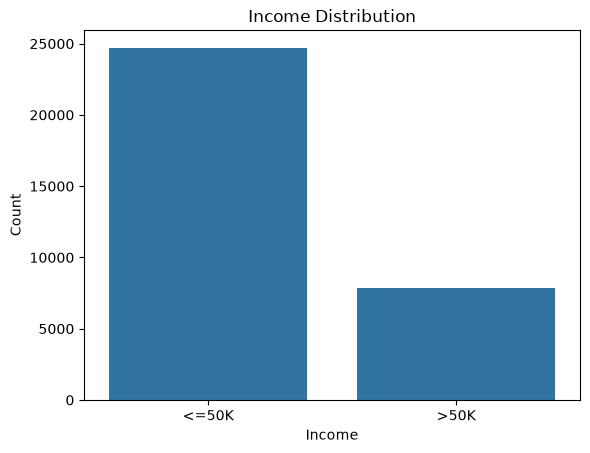

In [18]:
sns.countplot(data=df, x='income')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.show()

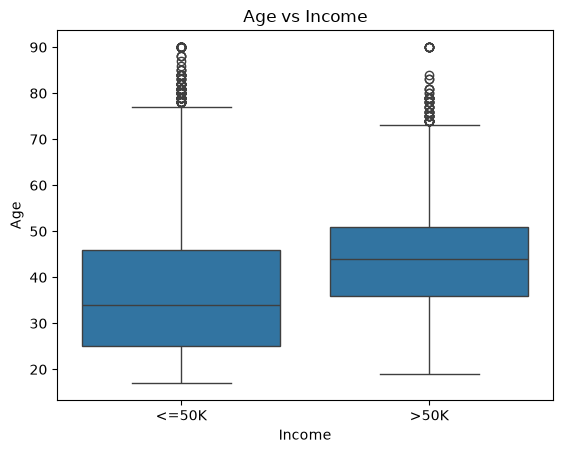

In [19]:
sns.boxplot(data=df, x='income', y='age')
plt.title('Age vs Income')
plt.xlabel('Income')
plt.ylabel('Age')
plt.show()

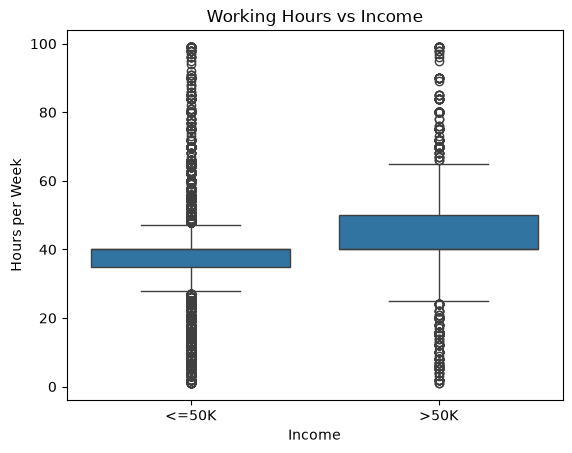

In [20]:
sns.boxplot(data=df, x='income', y='hours.per.week')
plt.title('Working Hours vs Income')
plt.xlabel('Income')
plt.ylabel('Hours per Week')
plt.show()

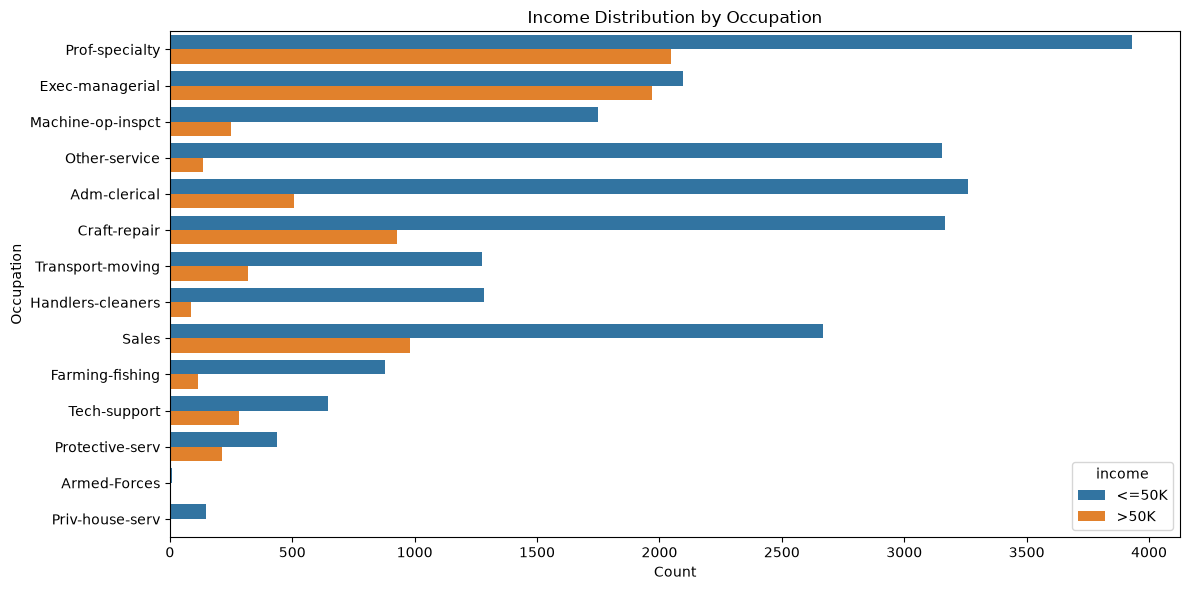

In [21]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, y='occupation', hue='income')

plt.title('Income Distribution by Occupation')
plt.xlabel('Count')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()

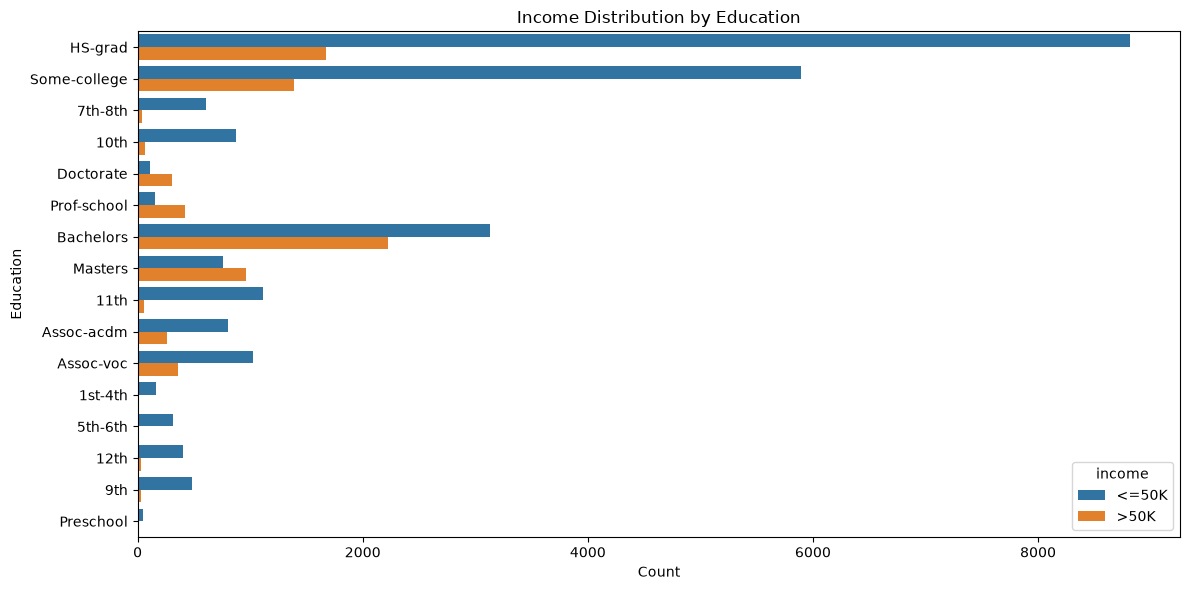

In [22]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, y='education', hue='income')

plt.title('Income Distribution by Education')
plt.xlabel('Count')
plt.ylabel('Education')
plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [26]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
}

In [27]:
pass


In [28]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (39516, 97)  y_train_smote =  (39516,)


In [29]:
y_train_smote.value_counts()

income
<=50K    19758
>50K     19758
Name: count, dtype: int64

In [30]:
results_smote = []

model_smote = LogisticRegression(max_iter=500, random_state=42)
model_smote.fit(X_train_smote, y_train_smote)
smote_pred = model_smote.predict(X_test)

results_smote.append({
    'Method': 'SMOTE Over Sampling',
    'Accuracy': accuracy_score(y_test, smote_pred),
    'Precision': precision_score(y_test, smote_pred, pos_label='>50K', zero_division=0),
    'Recall': recall_score(y_test, smote_pred, pos_label='>50K', zero_division=0),
    'F1-Score': f1_score(y_test, smote_pred, pos_label='>50K', zero_division=0)
})

pd.DataFrame(results_smote)


,Method,Accuracy,Precision,Recall,F1-Score
0,SMOTE Over Sampling,0.805624,0.566887,0.818878,0.669971


In [31]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (12542, 97)  y_train_rus =  (12542,)


In [32]:
y_train_rus.value_counts()

income
<=50K    6271
>50K     6271
Name: count, dtype: int64

In [33]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=50, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=50, random_state=42, n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}


  0%|          | 0/8 [00:00<?, ?it/s]


Logistic Regression

Confusion Matrix:
 [[4605  335]
 [ 638  930]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.88      0.93      0.90      4940
        >50K       0.74      0.59      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508



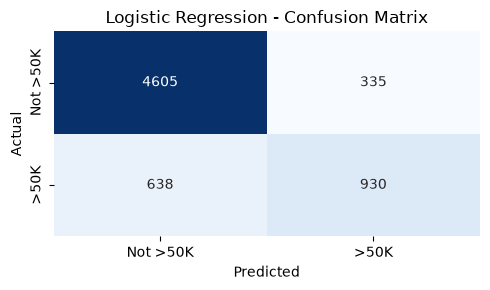

 12%|█▎        | 1/8 [00:01<00:10,  1.44s/it]

ROC-AUC: 0.8988
PR AUC: 0.7620

KNN

Confusion Matrix:
 [[4468  472]
 [ 694  874]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.87      0.90      0.88      4940
        >50K       0.65      0.56      0.60      1568

    accuracy                           0.82      6508
   macro avg       0.76      0.73      0.74      6508
weighted avg       0.81      0.82      0.82      6508



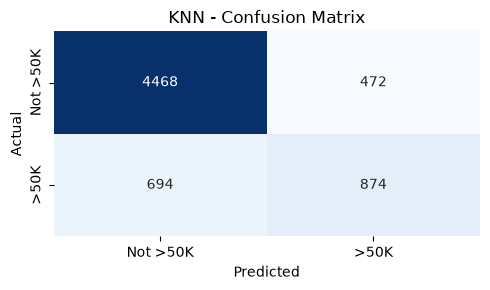

 25%|██▌       | 2/8 [00:07<00:23,  3.91s/it]

ROC-AUC: 0.8260
PR AUC: 0.5911

Decision Tree

Confusion Matrix:
 [[4295  645]
 [ 614  954]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.87      0.87      0.87      4940
        >50K       0.60      0.61      0.60      1568

    accuracy                           0.81      6508
   macro avg       0.74      0.74      0.74      6508
weighted avg       0.81      0.81      0.81      6508



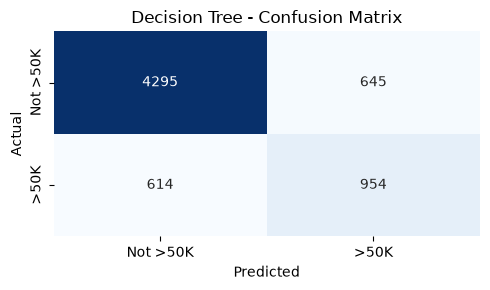

 38%|███▊      | 3/8 [00:08<00:14,  2.81s/it]

ROC-AUC: 0.7389
PR AUC: 0.4573

Naive Bayes

Confusion Matrix:
 [[1159 3781]
 [  50 1518]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.96      0.23      0.38      4940
        >50K       0.29      0.97      0.44      1568

    accuracy                           0.41      6508
   macro avg       0.62      0.60      0.41      6508
weighted avg       0.80      0.41      0.39      6508



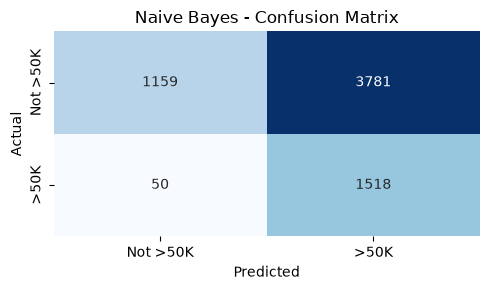

 50%|█████     | 4/8 [00:09<00:08,  2.14s/it]

ROC-AUC: 0.6662
PR AUC: 0.3255

Random Forest

Confusion Matrix:
 [[4577  363]
 [ 625  943]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.88      0.93      0.90      4940
        >50K       0.72      0.60      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.80      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508



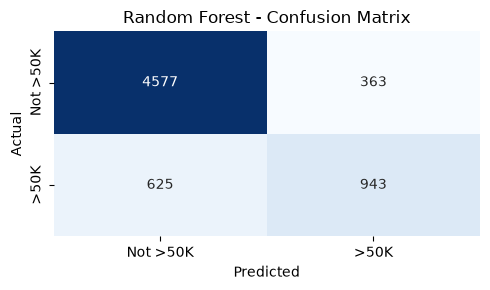

 62%|██████▎   | 5/8 [00:11<00:06,  2.00s/it]

ROC-AUC: 0.8895
PR AUC: 0.7369

Extra Trees

Confusion Matrix:
 [[4463  477]
 [ 646  922]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.87      0.90      0.89      4940
        >50K       0.66      0.59      0.62      1568

    accuracy                           0.83      6508
   macro avg       0.77      0.75      0.75      6508
weighted avg       0.82      0.83      0.82      6508



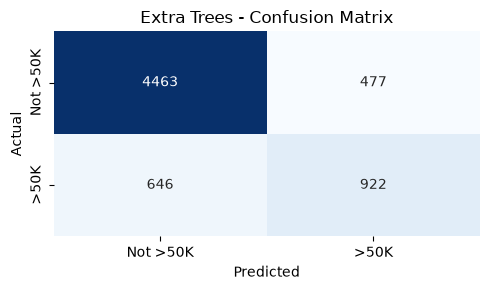

 75%|███████▌  | 6/8 [00:13<00:04,  2.07s/it]

ROC-AUC: 0.8658
PR AUC: 0.6614

AdaBoost

Confusion Matrix:
 [[4637  303]
 [ 678  890]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.87      0.94      0.90      4940
        >50K       0.75      0.57      0.64      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.75      0.77      6508
weighted avg       0.84      0.85      0.84      6508



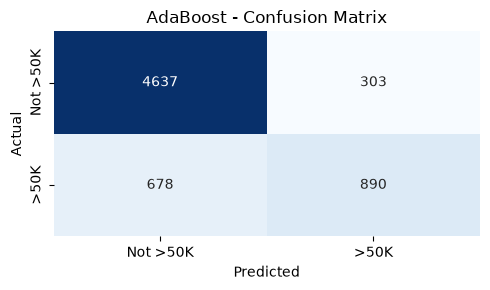

 88%|████████▊ | 7/8 [00:21<00:04,  4.03s/it]

ROC-AUC: 0.8981
PR AUC: 0.7666

Hist Gradient Boosting

Confusion Matrix:
 [[4640  300]
 [ 570  998]]

Classification Report:

              precision    recall  f1-score   support

    Not >50K       0.89      0.94      0.91      4940
        >50K       0.77      0.64      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508



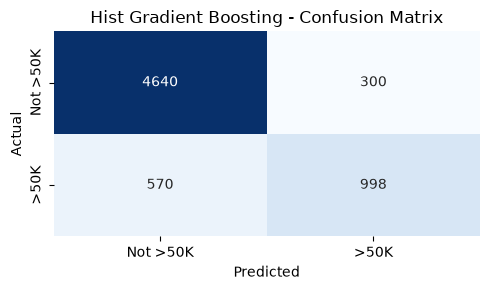

100%|██████████| 8/8 [00:25<00:00,  3.18s/it]

ROC-AUC: 0.9204
PR AUC: 0.8181


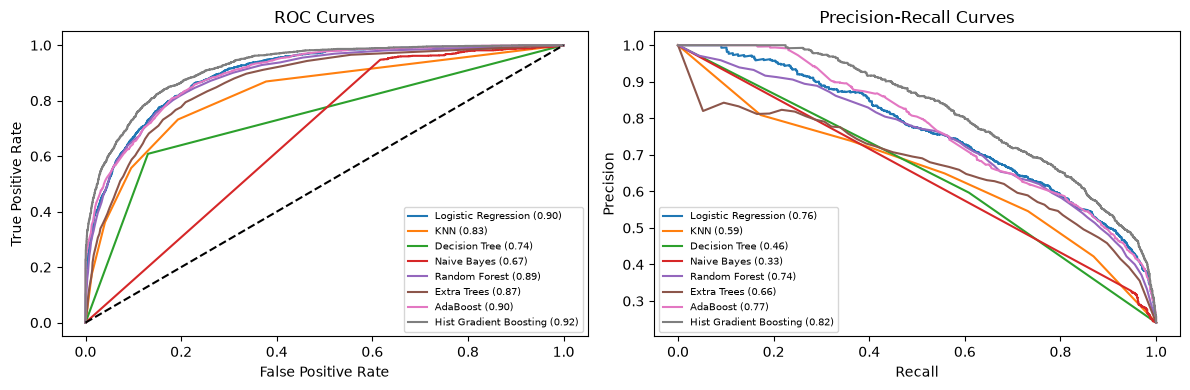

In [34]:
results = {}
roc_curves = {}
pr_curves = {}
positive_label = '>50K'
class_labels = ['<=50K', '>50K']

y_train = y.loc[y_train.index].astype(str).str.strip()
y_test = y.loc[y_test.index].astype(str).str.strip()

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    positive_index = list(model.classes_).index(positive_label)
    y_pred_prob = model.predict_proba(X_test)[:, positive_index]

    y_test_binary = (y_test == positive_label).astype(int)
    y_train_binary = (y_train == positive_label).astype(int)
    train_pred_binary = (train_pred == positive_label).astype(int)
    test_pred_binary = (test_pred == positive_label).astype(int)

    cm = confusion_matrix(y_test, test_pred, labels=class_labels)

    print(f"\n{name}")
    print("\nConfusion Matrix:\n", cm)
    print("\nClassification Report:\n")
    print(classification_report(
        y_test,
        test_pred,
        labels=class_labels,
        target_names=['Not >50K', '>50K'],
        zero_division=0
    ))

    plt.figure(figsize=(5, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['Not >50K', '>50K'],
        yticklabels=['Not >50K', '>50K']
    )
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{name} - Confusion Matrix')
    plt.tight_layout()
    plt.show()

    roc_auc = roc_auc_score(y_test_binary, y_pred_prob)
    pr_auc = average_precision_score(y_test_binary, y_pred_prob)

    fpr, tpr, _ = roc_curve(y_test_binary, y_pred_prob)
    precision_vals, recall_vals, _ = precision_recall_curve(
        y_test_binary, y_pred_prob
    )

    roc_curves[name] = (fpr, tpr, roc_auc)
    pr_curves[name] = (recall_vals, precision_vals, pr_auc)

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train_binary, train_pred_binary, zero_division=0),
        "Test Precision": precision_score(y_test_binary, test_pred_binary, zero_division=0),
        "Train Recall": recall_score(y_train_binary, train_pred_binary, zero_division=0),
        "Test Recall": recall_score(y_test_binary, test_pred_binary, zero_division=0),
        "Train F1 Score": f1_score(y_train_binary, train_pred_binary, zero_division=0),
        "Test F1 Score": f1_score(y_test_binary, test_pred_binary, zero_division=0),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train_binary, train_pred_binary),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test_binary, test_pred_binary),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"PR AUC: {pr_auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, (fpr, tpr, score) in roc_curves.items():
    axes[0].plot(fpr, tpr, label=f'{name} ({score:.2f})')

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves')
axes[0].legend(fontsize=7)

for name, (recall_vals, precision_vals, score) in pr_curves.items():
    axes[1].plot(recall_vals, precision_vals, label=f'{name} ({score:.2f})')

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()


In [35]:
pass


In [36]:
pass


In [37]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [38]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Hist Gradient Boosting,0.889008,0.866318,0.816075,0.768875,0.696221,0.636480,0.751398,0.696441,0.823209,0.787875,0.920425,0.818077
Logistic Regression,0.852511,0.850492,0.737222,0.735178,0.602615,0.593112,0.663157,0.656548,0.767220,0.762649,0.898820,0.761986
Random Forest,0.999539,0.848187,1.000000,0.722052,0.998086,0.601403,0.999042,0.656228,0.999043,0.763961,0.889453,0.736937
AdaBoost,0.853778,0.849262,0.753549,0.746018,0.584117,0.567602,0.658103,0.644694,0.761742,0.753133,0.898150,0.766578
Extra Trees,1.000000,0.827443,1.000000,0.659042,1.000000,0.588010,1.000000,0.621503,1.000000,0.745726,0.865761,0.661388
Decision Tree,1.000000,0.806546,1.000000,0.596623,1.000000,0.608418,1.000000,0.602463,1.000000,0.738926,0.738926,0.457342
KNN,0.876868,0.820836,0.776615,0.649331,0.686334,0.557398,0.728689,0.599863,0.811838,0.730926,0.826029,0.591085
Naive Bayes,0.413462,0.411340,0.287950,0.286469,0.974007,0.968112,0.444493,0.442114,0.604779,0.601364,0.666224,0.325533


<Axes: >

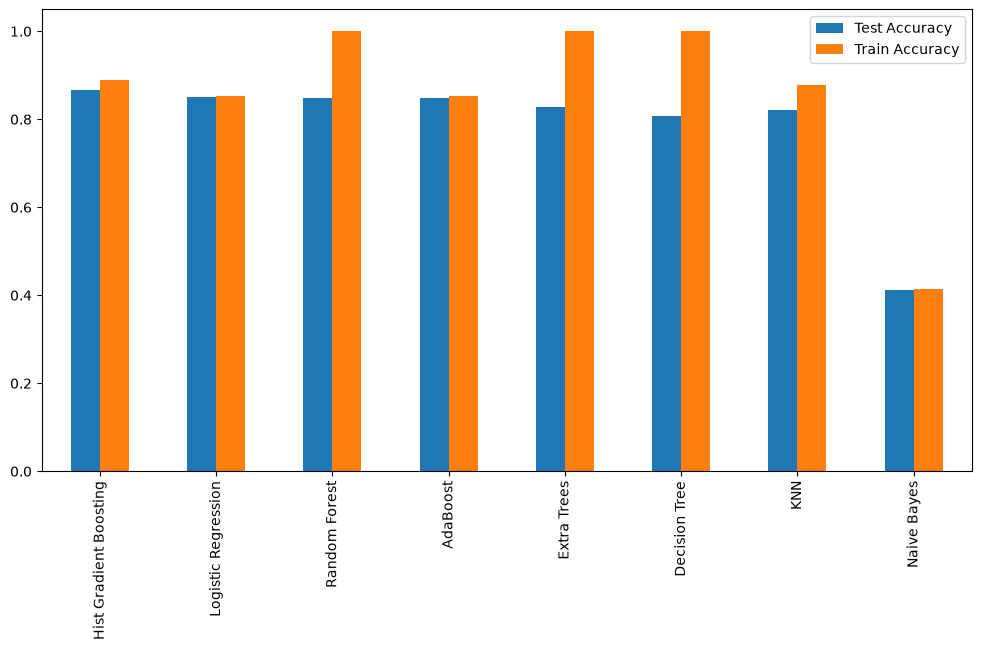

In [39]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

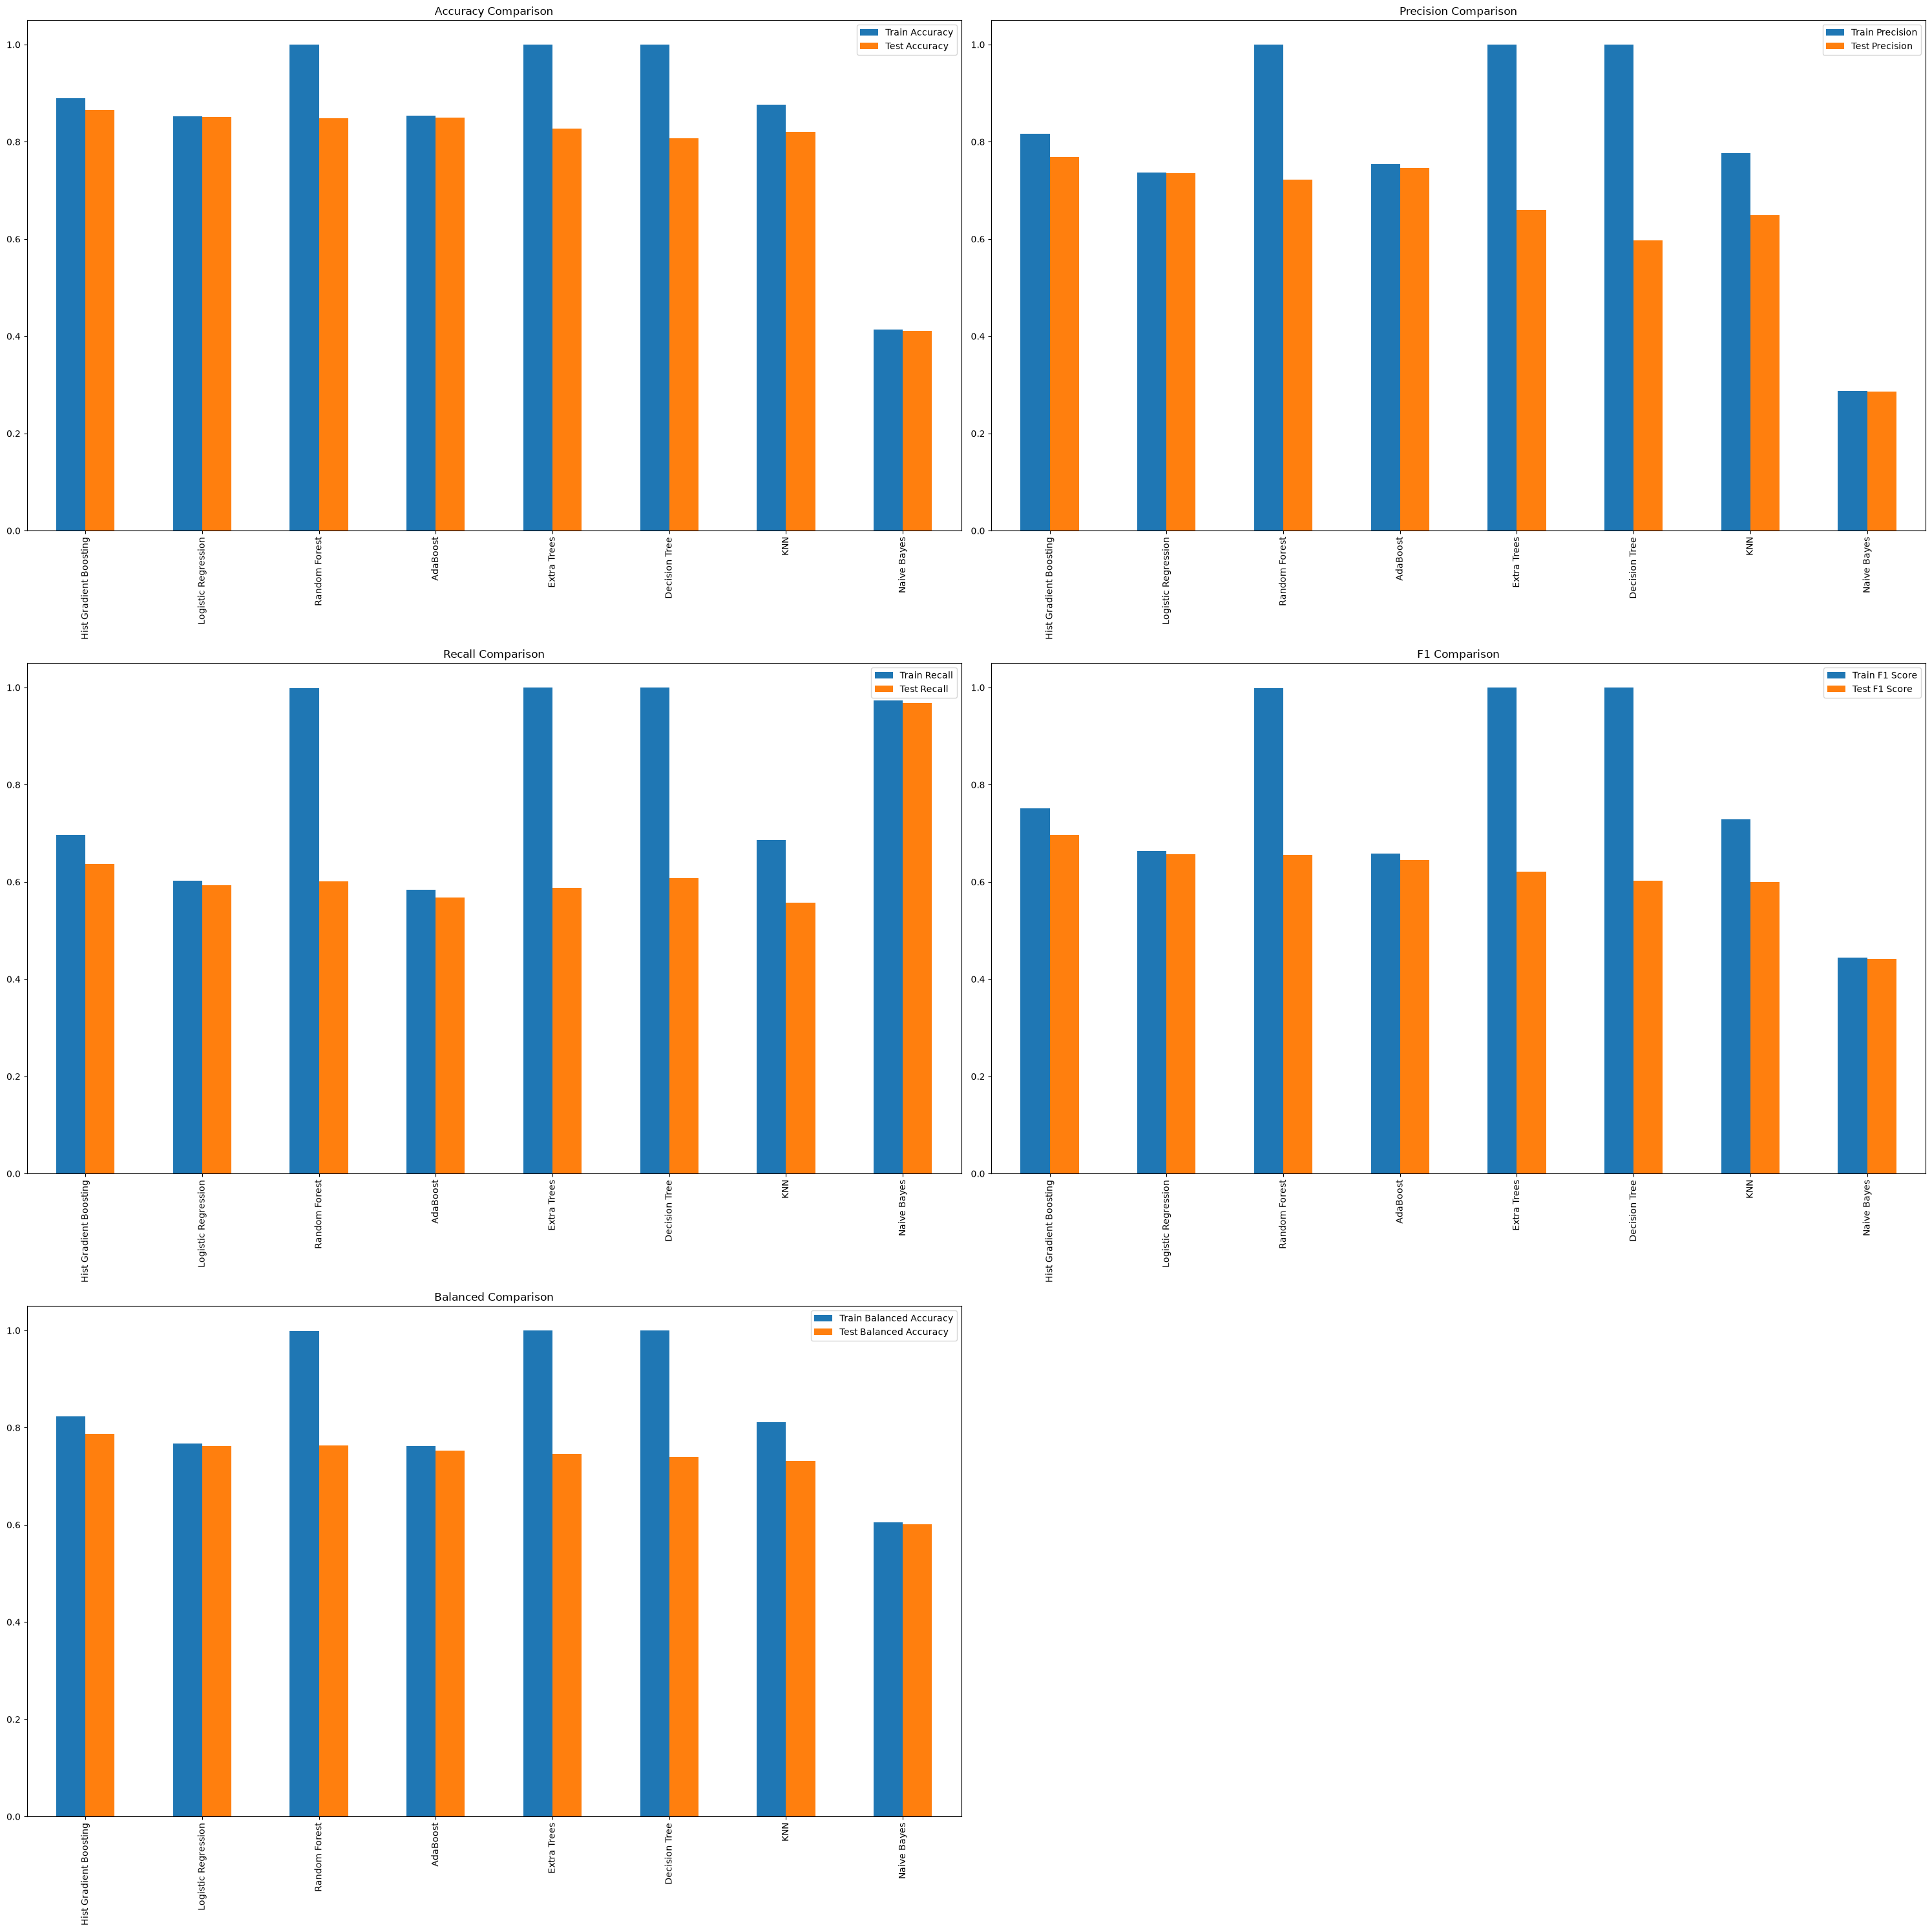

In [40]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)   
    results_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()